# Comparar runs

Este notebook só **lê** as pastas `runs/*/`, sem treinar nada. Para atualizar, rode tudo de novo.

- Cada experimento é uma **família**: um arquivo `config/runs/<familia>.py`, só com o que muda.
- Cada execução do `.\rodar.ps1 <familia>` cria uma run nova, `runs/<familia>_s<N>`, com a seed 1336 + N.
- O notebook junta as runs de cada família e compara as **médias**, qualquer que seja o número de runs.

Cada run deixa na sua pasta: `metricas.csv` (a curva), `resultado_test.json` (os acertos) e `erros_test.csv`.

## 1. Carregar as runs

In [1]:
import os
import re
import json
import glob
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:


FAMILIAS = []    # vazio = todas; ou uma lista, por exemplo ['abl_relu', 'par_iters6000']
TIPO = None      # None = todos; ou 'abl' (ablação), 'par' (parâmetro), 'out' (outros)
BASE = 'base'    # a família com que as outras são comparadas (sempre carregada)
SPLIT = 'test'

PARTES = ['comum', 'ruido', 'anos_dentro', 'anos_fora_209x', 'anos_fora_2100', 'formato']
TIPOS = ['valida', 'fronteira', 'dia_perto', 'dia_longe', 'mes_perto', 'mes_longe']

def familia_de(run):
    """'abl_relu_s2' -> 'abl_relu': o nome da run sem o sufixo _s<N>."""
    return re.sub(r'_s\d+$', '', run)

def tipo_de(familia):
    """'abl_relu' -> 'abl': o prefixo diz o tipo de experimento."""
    return familia.split('_')[0]

def entra(familia):
    if familia == BASE:
        return True
    if FAMILIAS and familia not in FAMILIAS:
        return False
    return TIPO is None or tipo_de(familia) == TIPO

curvas, resultados = [], []
for pasta in sorted(glob.glob('runs/*/')):
    run = os.path.basename(os.path.normpath(pasta))   # o nome vem da pasta
    familia = familia_de(run)
    if not entra(familia):
        continue
    if os.path.exists(os.path.join(pasta, 'metricas.csv')):
        c = pd.read_csv(os.path.join(pasta, 'metricas.csv'))
        c['run'], c['familia'] = run, familia
        curvas.append(c)
    arquivo = os.path.join(pasta, f'resultado_{SPLIT}.json')
    if os.path.exists(arquivo):
        with open(arquivo, encoding='utf-8') as f:
            r = json.load(f)
        r['run'], r['familia'] = run, familia
        resultados.append(r)

curvas = pd.concat(curvas, ignore_index=True)
print(f"{len(resultados)} runs com resultado, em {len({r['familia'] for r in resultados})} famílias")

3 runs com resultado, em 1 famílias


## 2. O que muda em cada família

As colunas da config que variam entre as famílias. A seed e a pasta ficam de fora, porque mudam de run para run.

In [3]:
configs = pd.DataFrame([r['config'] for r in resultados])
configs['familia'] = [r['familia'] for r in resultados]
configs['params'] = [r['params'] for r in resultados]
configs = configs.drop(columns=['seed', 'out_dir'], errors='ignore').drop_duplicates('familia').set_index('familia')
varia = [c for c in configs.columns if configs[c].astype(str).nunique() > 1]
configs[varia]

""
familia
base


## 3. Curvas de loss

- **Esquerda:** a loss de validação **média** de cada família, em escala log. A faixa vai do mínimo ao máximo entre as runs da família.
- **Direita:** treino contra validação de uma família (média). Se as duas se afastam, é overfitting.

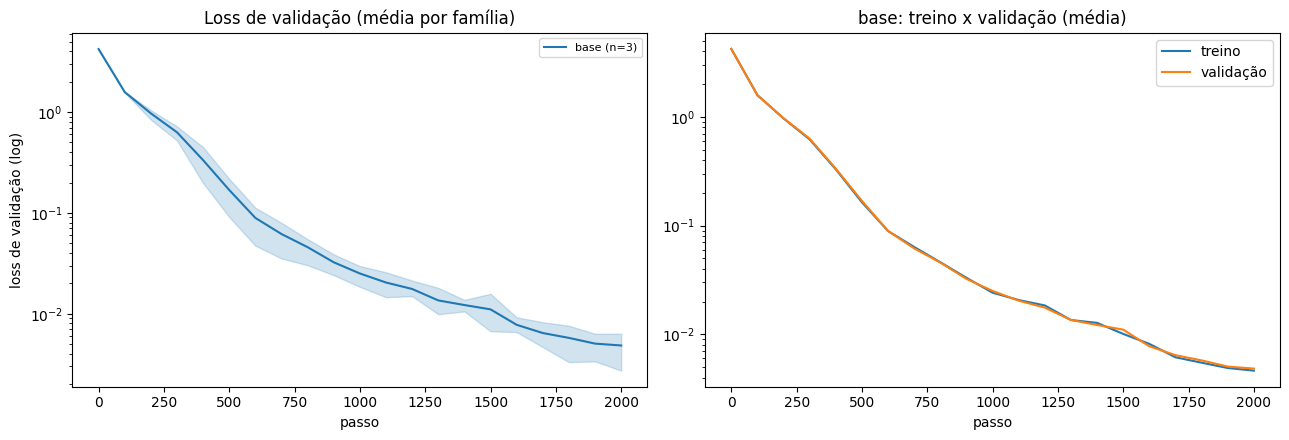

In [4]:
FAMILIA_DETALHE = BASE

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.5))
for familia, c in curvas.groupby('familia'):
    g = c.groupby('iter')['val_loss']
    n = c['run'].nunique()
    linha, = a.plot(g.mean().index, g.mean().values, label=f'{familia} (n={n})')
    if n > 1:
        a.fill_between(g.mean().index, g.min(), g.max(), color=linha.get_color(), alpha=0.2)
a.set_yscale('log')
a.set_xlabel('passo')
a.set_ylabel('loss de validação (log)')
a.set_title('Loss de validação (média por família)')
a.legend(fontsize=8)

c = curvas[curvas['familia'] == FAMILIA_DETALHE].groupby('iter')[['train_loss', 'val_loss']].mean()
b.plot(c.index, c['train_loss'], label='treino')
b.plot(c.index, c['val_loss'], label='validação')
b.set_yscale('log')
b.set_xlabel('passo')
b.set_title(f'{FAMILIA_DETALHE}: treino x validação (média)')
b.legend()
plt.tight_layout()
plt.show()

## 4. Tabela por run (detalhe)

Uma linha por run. Serve para ver quanto as runs de uma mesma família oscilam.
Os acertos estão em %. A fronteira, o mês impossível e a marca F são medidos **dentro do `comum`**.
- **precisão F:** das datas que o modelo marcou como inválidas, quantas eram mesmo.
- **recall F:** das datas inválidas, quantas o modelo marcou como inválidas.

In [5]:
linhas = []
for r in resultados:
    pt = r['parte_tipo']['comum']
    linha = {
        'run': r['run'],
        'familia': r['familia'],
        'seed': r['config'].get('seed'),
        'params': r['params'],
        'segundos': curvas.loc[curvas['run'] == r['run'], 'segundos'].max(),
        'best_val_loss': r['best_val_loss'],
    }
    for p in PARTES:
        linha[p] = 100 * r['por_parte'].get(p, float('nan'))
    linha['fronteira (comum)'] = 100 * pt.get('fronteira', float('nan'))
    linha['mês imp. (comum)'] = 100 * (pt.get('mes_perto', 0) + pt.get('mes_longe', 0)) / 2  # média simples dos dois
    marca = r.get('marca_F', {}).get('comum', {})   # precisão e recall da marca F, dentro do comum
    linha['precisão F (comum)'] = 100 * (marca.get('precisao') or float('nan'))
    linha['recall F (comum)'] = 100 * (marca.get('recall') or float('nan'))
    linhas.append(linha)

tabela = pd.DataFrame(linhas).set_index('run').sort_values(['familia', 'seed'])
METRICAS = PARTES + ['fronteira (comum)', 'mês imp. (comum)', 'precisão F (comum)', 'recall F (comum)']
tabela.style.format({'params': '{:,.0f}', 'segundos': '{:.0f}', 'best_val_loss': '{:.4f}',
                     **{m: '{:.1f}' for m in METRICAS}})

,familia,seed,params,segundos,best_val_loss,comum,ruido,anos_dentro,anos_fora_209x,anos_fora_2100,formato,fronteira (comum),mês imp. (comum),precisão F (comum),recall F (comum)
run,,,,,,,,,,,,,,,
base_s1,base,1337,"106,112",801,0.0055,99.2,96.4,99.0,85.0,0.0,0.0,95.4,94.4,99.2,97.3
base_s2,base,1338,"106,112",72,0.0027,99.7,97.8,99.8,99.7,26.5,0.0,100.0,99.5,99.5,99.7
base_s3,base,1339,"106,112",681,0.0063,98.6,96.2,98.6,89.0,0.0,0.0,100.0,97.1,97.9,99.4


## 5. Tabela por família (a principal)

Uma linha por família: a **média** das runs, com o desvio ao lado (`±`) quando há mais de uma run.
Ordenada pela média da loss de validação: é por ela que se escolhe a melhor config. O teste só é reportado.

In [6]:
COLUNAS = ['best_val_loss', 'segundos'] + METRICAS
grupos = tabela.groupby('familia')
media = grupos[COLUNAS].mean()
desvio = grupos[COLUNAS].std()     # vazio (NaN) quando a família tem uma run só
n_runs = grupos.size()
ordem = media.sort_values('best_val_loss').index

def media_desvio(m, d, casas):
    return f'{m:.{casas}f}' if pd.isna(d) else f'{m:.{casas}f} ± {d:.{casas}f}'

por_familia = pd.DataFrame({'n_runs': n_runs})
for col in COLUNAS:
    casas = 4 if col == 'best_val_loss' else 0 if col == 'segundos' else 1
    por_familia[col] = [media_desvio(m, d, casas) for m, d in zip(media[col], desvio[col])]
por_familia.loc[ordem]

,n_runs,best_val_loss,segundos,comum,ruido,anos_dentro,anos_fora_209x,anos_fora_2100,formato,fronteira (comum),mês imp. (comum),precisão F (comum),recall F (comum)
familia,,,,,,,,,,,,,
base,3,0.0048 ± 0.0019,518 ± 391,99.2 ± 0.5,96.8 ± 0.9,99.1 ± 0.6,91.2 ± 7.6,8.8 ± 15.3,0.0 ± 0.0,98.5 ± 2.7,97.0 ± 2.5,98.9 ± 0.8,98.8 ± 1.3


## 6. Acerto por parte do teste: médias por família, com o desvio como barra de erro

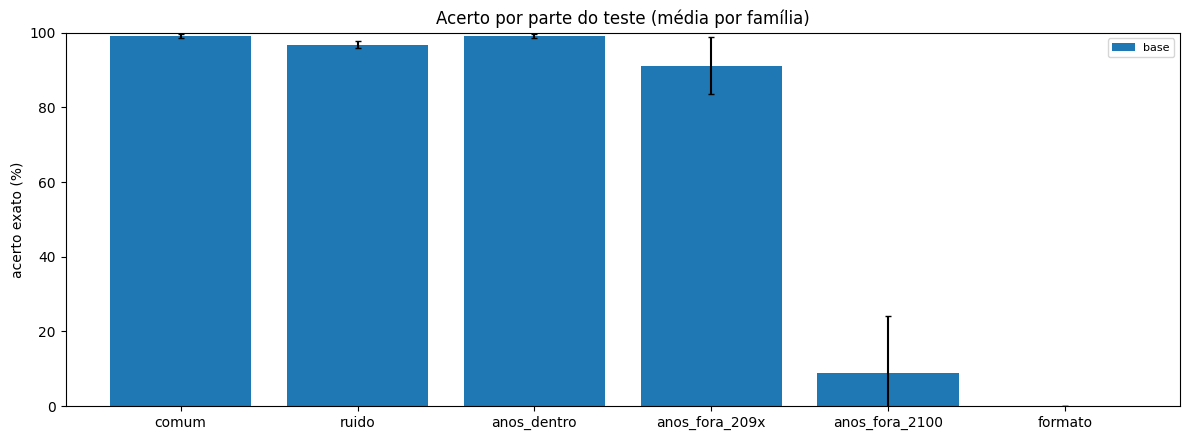

In [7]:
ax = media.loc[ordem, PARTES].T.plot.bar(yerr=desvio.loc[ordem, PARTES].T.fillna(0),
                                         figsize=(12, 4.5), width=0.8, capsize=2)
ax.set_ylabel('acerto exato (%)')
ax.set_ylim(0, 100)
ax.set_title('Acerto por parte do teste (média por família)')
ax.legend(fontsize=8, ncol=2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Comparação com a base

Cada célula é a **média da família menos a média da base**, em pontos percentuais.

A régua é **2 × o desvio da base** em cada métrica: o quanto a base varia só por sorte.
Diferenças menores que a régua aparecem em **cinza** (não dá para distinguir de sorte).
As maiores aparecem em verde (melhor) ou vermelho (pior). A régua só existe com 2 ou mais runs da base.

In [8]:
if BASE not in media.index:
    print(f"a família '{BASE}' ainda não tem runs")
else:
    regua = 2 * desvio.loc[BASE, METRICAS]
    delta = (media[METRICAS] - media.loc[BASE, METRICAS]).drop(BASE).loc[[f for f in ordem if f != BASE]]
    delta.insert(0, 'n_runs', n_runs[delta.index])

    def cor(coluna):
        if coluna.name == 'n_runs':
            return [''] * len(coluna)
        limite = regua[coluna.name]
        return ['color: #999999' if pd.notna(limite) and abs(v) < limite
                else 'color: green; font-weight: bold' if v > 0
                else 'color: red; font-weight: bold' if v < 0 else '' for v in coluna]

    print(f"base com {n_runs[BASE]} runs. Régua (2 × desvio da base), em pontos:")
    display(regua.to_frame('régua').T.style.format('{:.1f}', na_rep='—'))
    display(delta.style.format({m: '{:+.1f}' for m in METRICAS}).apply(cor, axis=0))

base com 3 runs. Régua (2 × desvio da base), em pontos:


,comum,ruido,anos_dentro,anos_fora_209x,anos_fora_2100,formato,fronteira (comum),mês imp. (comum),precisão F (comum),recall F (comum)
régua,1.0,1.8,1.2,15.2,30.6,0.1,5.4,5.1,1.7,2.6


,n_runs,comum,ruido,anos_dentro,anos_fora_209x,anos_fora_2100,formato,fronteira (comum),mês imp. (comum),precisão F (comum),recall F (comum)
familia,,,,,,,,,,,


## 8. Uma run por dentro: parte x tipo, e por campo

- **Mapa:** o acerto de cada tipo de data dentro de cada parte. É a leitura correta do "por tipo".
- **Tabela por campo:** onde está o erro: no ano, no mês, no dia ou só na marca `T`/`F`.

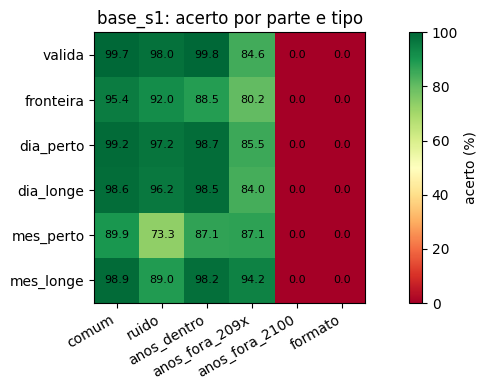

,ano,mes,dia,marca
comum,100.0,100.0,99.9,99.3
ruido,99.5,99.2,99.4,97.9
anos_dentro,100.0,100.0,99.9,99.1
anos_fora_209x,85.8,100.0,99.9,99.2
anos_fora_2100,0.0,99.9,99.8,98.9
formato,0.4,0.3,69.3,35.6


In [9]:
RUN_MAPA = f'{BASE}_s1'

r = next(r for r in resultados if r['run'] == RUN_MAPA)
mapa = pd.DataFrame(r['parte_tipo']).reindex(index=TIPOS, columns=PARTES) * 100

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(mapa, cmap='RdYlGn', vmin=0, vmax=100)
ax.set_xticks(range(len(PARTES)), PARTES, rotation=30, ha='right')
ax.set_yticks(range(len(TIPOS)), TIPOS)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iat[i, j]
        ax.text(j, i, '' if pd.isna(v) else f'{v:.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, label='acerto (%)')
ax.set_title(f'{RUN_MAPA}: acerto por parte e tipo')
plt.tight_layout()
plt.show()

por_campo = pd.DataFrame(r['por_campo']).reindex(columns=PARTES).T * 100
por_campo.style.format('{:.1f}')

## 9. Exemplos de erro

In [10]:
RUN_ERROS = f'{BASE}_s1'
PARTE_ERROS = 'comum'   # comum, ruido, formato, anos_dentro ou anos_fora
N = 10

erros = pd.read_csv(f'runs/{RUN_ERROS}/erros_{SPLIT}.csv', dtype=str, keep_default_na=False)
sel = erros[erros['parte'] == PARTE_ERROS]
print(f"{len(sel):,} erros na parte {PARTE_ERROS}")
sel.sample(min(N, len(sel)), random_state=0)[['input', 'previsto', 'target', 'tipo', 'formato', 'ruido']]

623 erros na parte comum


,input,previsto,target,tipo,formato,ruido
19842,9/71/1916,1916-71-09T,1916-71-09F,mes_longe,barra_sem_zero,nenhum
19018,4/0/2052,2052-00-04T,2052-00-04F,mes_perto,barra_sem_zero,nenhum
20922,22/0/1981,1981-00-22T,1981-00-22F,mes_perto,barra_sem_zero,nenhum
19185,23/0/2074,2074-00-23T,2074-00-23F,mes_perto,barra_sem_zero,nenhum
20951,21/0/1907,1907-00-21T,1907-00-21F,mes_perto,barra_sem_zero,nenhum
2212,31/12/1947,1947-12-31F,1947-12-31T,valida,barra,nenhum
17464,trinta e nove de agosto de 1921,1921-08-32F,1921-08-39F,dia_perto,dia_extenso,nenhum
21392,8/79/1946,1946-7-08F,1946-79-08F,mes_longe,barra_sem_zero,nenhum
19856,13/0/1946,1946-00-13T,1946-00-13F,mes_perto,barra_sem_zero,nenhum
16927,cinquenta e um de novembro de 2042,2042-11-50F,2042-11-51F,dia_longe,dia_extenso,nenhum
